# Track A: Fruit Ripeness & Defect Grading
## Deep Learning Pipeline | MobileNetV3-Small + SE Attention | PyTorch
### Yunnan University - Computer Vision Final Project

**Pipeline Overview:**
1. Mount Google Drive & load dataset
2. Custom Dataset + Transforms
3. MobileNetV3 + SE Block (Bonus)
4. Training & Validation loops with checkpointing
5. Full evaluation: Confusion Matrix, ROC-AUC, Classification Report
6. Ablation Study
7. Console Inference Demo

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# EXTRACT DATA
import os
import zipfile
!rm -rf /content/fruit_ripeness_dataset
!unzip -q /content/drive/MyDrive/fruit_ripeness_dataset.zip -d /content/

## Step 1: Install Dependencies & Import Libraries
All required packages come pre-installed on Google Colab.
We import everything upfront so missing dependencies surface immediately.

In [ ]:
# Standard library
import os
import random
import time
import copy

# Numerical & plotting
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch core
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

# Torchvision
import torchvision.transforms as transforms
import torchvision.models as models

# Scikit-learn evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.preprocessing import label_binarize

# Image loading
from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

# Device selection
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {DEVICE}")
if DEVICE.type == "cuda":
    print(f" GPU             : {torch.cuda.get_device_name(0)}")

PyTorch version : 2.11.0+cu128
Using device    : cuda
 GPU             : Tesla T4


## Step 2: Dataset Paths & Hyperparameter Matrix
All hyperparameters are defined here in one place.
Changing any value automatically propagates through the entire notebook.

In [ ]:
DATA_ROOT = "/content/fruit_ripeness_dataset/dataset"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
TEST_DIR  = os.path.join(DATA_ROOT, "test",)

# Model save directory
SAVE_DIR = "/content/drive/MyDrive/cv_project_v2/saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

BEST_MODEL_PATH    = os.path.join(SAVE_DIR, "best_model_v2.pth")
FINAL_MODEL_PATH   = os.path.join(SAVE_DIR, "final_model_v2.pth")
ABLATION_AUG_PATH  = os.path.join(SAVE_DIR, "ablation_with_aug_v2.pth")
ABLATION_NOAUG_PATH= os.path.join(SAVE_DIR, "ablation_no_aug_v2.pth")

# Hyperparameter Matrix
IMG_SIZE     = 224
BATCH_SIZE   = 64
NUM_EPOCHS   = 30
LR           = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS  = 4
VAL_SPLIT    = 0.15

# Verify directories exist
print("Directory Check ......")
for name, path in [("Train", TRAIN_DIR), ("Test", TEST_DIR), ("Save", SAVE_DIR)]:
    status = "Found" if os.path.isdir(path) else "NOT FOUND - check path"
    print(f"  {name:<6}: {path}  →  {status}")

Directory Check ......
  Train : /content/fruit_ripeness_dataset/dataset/train  →  Found
  Test  : /content/fruit_ripeness_dataset/dataset/test  →  Found
  Save  : /content/drive/MyDrive/cv_project_v2/saved_models  →  Found


## Step 3: Custom Dataset Class
Explicitly filters `self.classes` to only include valid subdirectories,
handling folder names with spaces and skipping any stray files at root level.

In [ ]:
class CustomFruitDataset(Dataset):
    """
    Reads a folder structured as:
        root_dir/
            class_a/     ← may contain spaces in name
            class_b/
            ...

    Builds a flat list of (image_path, integer_label) tuples.
    Only counts subfolders as classes — ignores stray files at root level.
    """

    def __init__(self, root_dir, transform=None):
        self.root_dir  = root_dir
        self.transform = transform
        self.samples   = []

        all_entries = os.listdir(root_dir)
        self.classes = sorted([
            entry for entry in all_entries
            if os.path.isdir(os.path.join(root_dir, entry))
            and not entry.startswith('.')
        ])

        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}

        # Walk each class folder and collect image paths
        for class_name in self.classes:
            class_folder = os.path.join(root_dir, class_name)
            collected = 0
            for fname in sorted(os.listdir(class_folder)):
                if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    full_path = os.path.join(class_folder, fname)
                    label     = self.class_to_idx[class_name]
                    self.samples.append((full_path, label))
                    collected += 1
            print(f"    {class_name:<25} → {collected} images  (label {self.class_to_idx[class_name]})")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]

        # convert
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

print("Training Dataset Probe")
_probe = CustomFruitDataset(TRAIN_DIR)
print(f"\n  Total classes  : {len(_probe.classes)}")
print(f"  class_to_idx   : {_probe.class_to_idx}")
print(f"  Total samples  : {len(_probe)}")

Training Dataset Probe
    freshapples               → 1693 images  (label 0)
    freshbanana               → 1581 images  (label 1)
    freshoranges              → 1466 images  (label 2)
    rottenapples              → 2342 images  (label 3)
    rottenbanana              → 2224 images  (label 4)
    rottenoranges             → 1595 images  (label 5)
    unripe apple              → 1934 images  (label 6)
    unripe banana             → 2097 images  (label 7)
    unripe orange             → 1285 images  (label 8)

  Total classes  : 9
  class_to_idx   : {'freshapples': 0, 'freshbanana': 1, 'freshoranges': 2, 'rottenapples': 3, 'rottenbanana': 4, 'rottenoranges': 5, 'unripe apple': 6, 'unripe banana': 7, 'unripe orange': 8}
  Total samples  : 16217


## Step 4: Transform Pipelines

Two distinct pipelines are defined:

| Pipeline | Used For | Augmentation |
|---|---|---|
| `train_transform` | Training set |  Yes - combats overfitting |
| `base_transform` | Val / Test / Inference | No - deterministic evaluation |

**Why ImageNet normalization stats?**
MobileNetV3's pretrained weights learned from ImageNet's pixel distribution.
Normalizing with the same mean/std aligns our input space to what the
pretrained feature extractor expects, maximizing transfer learning efficiency.

In [ ]:
# Training transform
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Augmentation block
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2,
        hue=0.05
    ),
    transforms.RandomGrayscale(p=0.05),

    # Conversion + normalization
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Base transform: no augmentation used for val, test, and inference
base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

print("train_transform steps:", len(train_transform.transforms))
print("base_transform  steps:", len(base_transform.transforms))

train_transform steps: 8
base_transform  steps: 3


## Step 5: Build Datasets & Carve Validation Split

Since the dataset only provides `train/` and `test/`, we carve 15% of
training data as a validation set using `random_split`.

**Key design decisions:**
- Split happens AFTER building the full dataset so class mappings stay consistent
- `manual_seed` on the generator ensures the same images go to val every run
- Validation subset receives `base_transform` (no augmentation) for honest metrics
- Test set is never touched until final evaluation

In [ ]:
# Build full training dataset
full_train_dataset = CustomFruitDataset(TRAIN_DIR, transform=train_transform)
total_train        = len(full_train_dataset)

# Guard: catch empty dataset before split
assert total_train > 0, (
    f"Dataset is empty! Check TRAIN_DIR path:\n  {TRAIN_DIR}\n"
    f"  Exists: {os.path.isdir(TRAIN_DIR)}"
)

# Compute split sizes
val_count   = int(total_train * VAL_SPLIT)
train_count = total_train - val_count

assert val_count   > 0, f"val_count is 0 — reduce VAL_SPLIT or add more data"
assert train_count > 0, f"train_count is 0 — reduce VAL_SPLIT or add more data"

# Reproducible split
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(
    full_train_dataset,
    [train_count, val_count],
    generator=generator
)

# Val subset with clean transform (no augmentation)
val_dataset_clean = CustomFruitDataset(TRAIN_DIR, transform=base_transform)

class SubsetWithTransform(Dataset):
    """Wraps a Subset and applies a different transform than the parent dataset."""
    def __init__(self, subset, dataset_with_transform):
        self.indices = subset.indices
        self.dataset = dataset_with_transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        # Remap local index → original dataset index
        return self.dataset[self.indices[idx]]

val_subset_clean = SubsetWithTransform(val_subset, val_dataset_clean)

# Test dataset
test_dataset = CustomFruitDataset(TEST_DIR, transform=base_transform)

assert len(test_dataset) > 0, (
    f"Test dataset is empty! Check TEST_DIR:\n  {TEST_DIR}"
)

# DataLoaders
train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
val_loader = DataLoader(
    val_subset_clean,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

NUM_CLASSES = len(full_train_dataset.classes)
class_names = full_train_dataset.classes

print("Split Summary .......")
print(f"  Full train pool : {total_train} images")
print(f"  Train subset  : {train_count}  ({100*(1-VAL_SPLIT):.0f}%)")
print(f"  Val subset    : {val_count}   ({100*VAL_SPLIT:.0f}%)")
print(f"  Test set        : {len(test_dataset)} images")
print(f"  Classes ({NUM_CLASSES})    : {class_names}")
print()
imgs, lbls = next(iter(train_loader))
print(f"  Sample batch → images: {imgs.shape}  labels: {lbls.shape}")

    freshapples               → 1693 images  (label 0)
    freshbanana               → 1581 images  (label 1)
    freshoranges              → 1466 images  (label 2)
    rottenapples              → 2342 images  (label 3)
    rottenbanana              → 2224 images  (label 4)
    rottenoranges             → 1595 images  (label 5)
    unripe apple              → 1934 images  (label 6)
    unripe banana             → 2097 images  (label 7)
    unripe orange             → 1285 images  (label 8)
    freshapples               → 1693 images  (label 0)
    freshbanana               → 1581 images  (label 1)
    freshoranges              → 1466 images  (label 2)
    rottenapples              → 2342 images  (label 3)
    rottenbanana              → 2224 images  (label 4)
    rottenoranges             → 1595 images  (label 5)
    unripe apple              → 1934 images  (label 6)
    unripe banana             → 2097 images  (label 7)
    unripe orange             → 1285 images  (label 8)
    fresha

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  Sample batch → images: torch.Size([64, 3, 224, 224])  labels: torch.Size([64])


## Step 6: SE Block + MobileNetV3 Architecture (Bonus +5 pts)

### Squeeze-and-Excitation Block
Hu et al. (2018) - learns *which feature channels matter* for classification.

In [ ]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super(SEBlock, self).__init__()
        self.squeeze    = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels, max(channels // reduction_ratio, 1)),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction_ratio, 1), channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, h, w = x.shape

        # Step 1 Squeeze
        z = self.squeeze(x)

        # Step 2 Excite
        s = self.excitation(z)
        s = s.view(b, c, 1, 1)

        # Step 3 Scale
        return x * s

# MobileNetV3-Small
def build_model(num_classes, device):
    model = models.mobilenet_v3_small(
        weights=models.MobileNet_V3_Small_Weights.DEFAULT
    )

    last_conv_block = model.features[-1]
    model.features[-1] = nn.Sequential(
        last_conv_block,
        SEBlock(channels=576, reduction_ratio=16)
    )

    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)

    return model.to(device)


# Build model
model = build_model(NUM_CLASSES, DEVICE)

# Verify shapes with a dummy forward pass
dummy  = torch.zeros(2, 3, 224, 224).to(DEVICE)
out    = model(dummy)
assert out.shape == (2, NUM_CLASSES), \
    f"Shape mismatch! Got {out.shape}, expected (2, {NUM_CLASSES})"

# Count total parameters
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model Summary")
print(f"  Backbone        : MobileNetV3-Small + SE Block")
print(f"  Output classes  : {num_classes if (num_classes := NUM_CLASSES) else NUM_CLASSES}")
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable_params:,}")
print(f"  Dummy output     : {out.shape}")
print(f"\n  Classifier head :")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 183MB/s]


Model Summary
  Backbone        : MobileNetV3-Small + SE Block
  Output classes  : 9
  Total params    : 1,569,165
  Trainable params: 1,569,165
  Dummy output     : torch.Size([2, 9])

  Classifier head :
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=9, bias=True)
)


## Step 7: Loss Function, Optimizer & Scheduler

| Component | Choice | Reason |
|---|---|---|
| Loss | `CrossEntropyLoss` | Combines LogSoftmax + NLLLoss in one numerically stable op |
| Optimizer | `Adam` | Adaptive per-parameter LR; faster convergence than SGD for fine-tuning |
| Scheduler | `ReduceLROnPlateau` | Halves LR after 3 stagnant val-loss epochs; prevents overshooting |

In [ ]:
# CrossEntropyLoss = LogSoftmax + NLLLoss
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)

print("Criterion :", criterion)
print("Optimizer :", type(optimizer).__name__, f"  lr={LR}  wd={WEIGHT_DECAY}")
print("Scheduler : ReduceLROnPlateau  patience=3  factor=0.5")
print(f"Current LR: {optimizer.param_groups[0]['lr']}")

Criterion : CrossEntropyLoss()
Optimizer : Adam   lr=0.0001  wd=0.0001
Scheduler : ReduceLROnPlateau  patience=3  factor=0.5
Current LR: 0.0001


## Step 8: Training & Validation Loop

Full explicit training loop with:
- Per-epoch train loss + accuracy tracking
- Per-epoch validation loss + accuracy tracking
- **Best model checkpoint** saved whenever val_loss improves
- **Final model** saved after all epochs complete
- Learning rate scheduling based on validation loss

## Step 8.1: Phase 1 - Training Loop
Run this cell to train for all epochs.
Each epoch prints: Train Loss, Train Accuracy, elapsed time.

In [ ]:
import sys

# History & checkpoint init
history = {
    "train_loss": [], "val_loss": [],
    "train_acc" : [], "val_acc" : []
}
best_val_loss  = float('inf')
best_model_wts = copy.deepcopy(model.state_dict())

print("Training Started", flush=True)
print(f"  Epochs     : {NUM_EPOCHS}",    flush=True)
print(f"  Batch size : {BATCH_SIZE}",    flush=True)
print(f"  Device     : {DEVICE}",        flush=True)
print(f"  Classes    : {class_names}\n", flush=True)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # Phase 1 Training
    model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0
    num_batches = len(train_loader)

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Zero gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(images)

        # Compute scalar loss (CrossEntropy over the batch)
        loss = criterion(logits, labels)

        # Backward pass
        loss.backward()

        # Gradient descent
        optimizer.step()

        # Accumulate weighted loss
        train_loss_sum += loss.item() * images.size(0)

        # Predicted class
        preds          = logits.argmax(dim=1)
        train_correct  += (preds == labels).sum().item()
        train_total    += labels.size(0)

        print(
            f"\r  Epoch [{epoch:02d}/{NUM_EPOCHS}] "
            f"Batch [{batch_idx+1:03d}/{num_batches}] "
            f"Loss: {loss.item():.4f}",
            end='', flush=True
        )

    train_loss = train_loss_sum / train_total
    train_acc  = train_correct  / train_total

    # Phase 2 Validation
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss   = criterion(logits, labels)

            val_loss_sum  += loss.item() * images.size(0)
            preds          = logits.argmax(dim=1)
            val_correct   += (preds == labels).sum().item()
            val_total     += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total

    # Step LR scheduler based on validation loss
    scheduler.step(val_loss)

    # Save best model checkpoint
    saved_tag = ""
    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save({
            "epoch"            : epoch,
            "model_state_dict" : model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss"         : val_loss,
            "val_acc"          : val_acc,
            "class_to_idx"     : full_train_dataset.class_to_idx,
            "num_classes"      : NUM_CLASSES,
        }, BEST_MODEL_PATH)
        saved_tag = "best saved"

    # Record history
    history["train_loss"].append(train_loss)
    history["val_loss"]  .append(val_loss)
    history["train_acc"] .append(train_acc)
    history["val_acc"]   .append(val_acc)

    elapsed = time.time() - epoch_start

    print(
        f"\r  Epoch [{epoch:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}  |  "
        f"Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.4f}  |  "
        f"{elapsed:.1f}s"
        f"{saved_tag}",
        flush=True
    )

# Save final model (last epoch weights, regardless of best)
torch.save({
    "epoch"               : NUM_EPOCHS,
    "model_state_dict"    : model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "val_loss"            : val_loss,
    "val_acc"             : val_acc,
    "class_to_idx"        : full_train_dataset.class_to_idx,
    "num_classes"         : NUM_CLASSES,
}, FINAL_MODEL_PATH)

print(f"Training complete.")
print(f"Best val loss  : {best_val_loss:.4f}")
print(f"Best model saved  : {BEST_MODEL_PATH}")
print(f"Final model saved : {FINAL_MODEL_PATH}")
sys.stdout.flush()

print(f"\n Training complete.",          flush=True)
print(f" Best val loss  : {best_val_loss:.4f}", flush=True)
print(f" Best model  : {BEST_MODEL_PATH}",     flush=True)
print(f" Final model : {FINAL_MODEL_PATH}",    flush=True)

Training Started
  Epochs     : 30
  Batch size : 64
  Device     : cuda
  Classes    : ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges', 'unripe apple', 'unripe banana', 'unripe orange']

  Epoch [01/30] Train Loss: 0.7262  Train Acc: 0.7708  |  Val Loss: 0.2722  Val Acc: 0.8931  |  147.3sbest saved
  Epoch [02/30] Train Loss: 0.2045  Train Acc: 0.9212  |  Val Loss: 0.1323  Val Acc: 0.9482  |  142.3sbest saved
  Epoch [03/30] Train Loss: 0.1360  Train Acc: 0.9473  |  Val Loss: 0.1015  Val Acc: 0.9642  |  145.4sbest saved
  Epoch [04/30] Train Loss: 0.1003  Train Acc: 0.9631  |  Val Loss: 0.0720  Val Acc: 0.9749  |  143.4sbest saved
  Epoch [05/30] Train Loss: 0.0754  Train Acc: 0.9755  |  Val Loss: 0.0484  Val Acc: 0.9803  |  144.2sbest saved
  Epoch [06/30] Train Loss: 0.0674  Train Acc: 0.9744  |  Val Loss: 0.0415  Val Acc: 0.9840  |  143.3sbest saved
  Epoch [07/30] Train Loss: 0.0558  Train Acc: 0.9806  |  Val Loss: 0.0403  Val Acc: 0.

## Step 9: Training Curves
Plot **Train vs Validation Loss** and **Train vs Validation Accuracy**.
Required artifact for **Chapter 2** of the technical report.
Overfitting is visible when val_loss diverges upward while train_loss keeps falling.

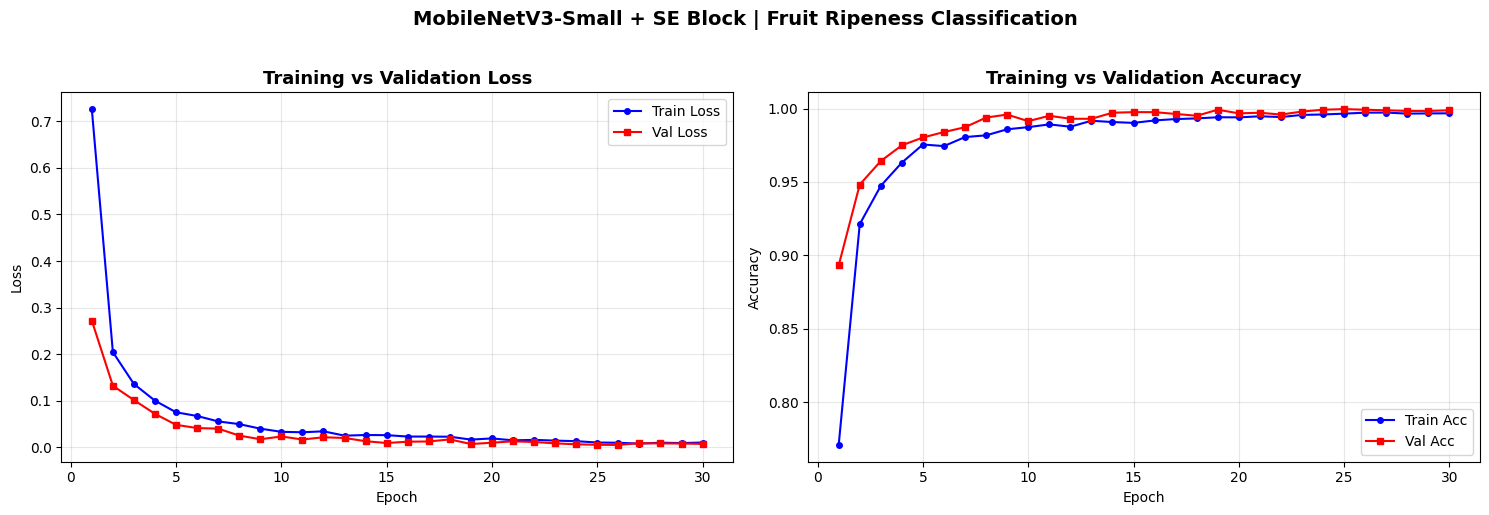

Saved /content/drive/MyDrive/cv_project_v2/saved_models/training_curves.png


In [ ]:
epochs_x = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss curves
ax1.plot(epochs_x, history["train_loss"], 'b-o', label="Train Loss", markersize=4)
ax1.plot(epochs_x, history["val_loss"],   'r-s', label="Val Loss",   markersize=4)
ax1.set_title("Training vs Validation Loss", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.legend(); ax1.grid(True, alpha=0.3)

# Accuracy curves
ax2.plot(epochs_x, history["train_acc"], 'b-o', label="Train Acc", markersize=4)
ax2.plot(epochs_x, history["val_acc"],   'r-s', label="Val Acc",   markersize=4)
ax2.set_title("Training vs Validation Accuracy", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle("MobileNetV3-Small + SE Block | Fruit Ripeness Classification",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

curve_path = os.path.join(SAVE_DIR, "training_curves.png")
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {curve_path}")

## Step 10: Test Set Evaluation
Load the **best checkpoint** (lowest val loss) and evaluate on the
completely unseen test set. Generates three required Chapter 3 artifacts:

1. Classification Report: per-class Precision, Recall, F1, Accuracy
2. Confusion Matrix heatmap
3. Multi-class ROC-AUC curves (One-vs-Rest)

In [ ]:
# Load best checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"  Loaded best checkpoint from epoch {checkpoint['epoch']}")
print(f"  Val loss at checkpoint: {checkpoint['val_loss']:.4f}")
print(f"  Val acc  at checkpoint: {checkpoint['val_acc']:.4f}")

model.eval()

all_labels = []
all_preds  = []
all_probs  = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        logits = model(images)
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_preds .extend(preds.cpu().numpy())
        all_probs .extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)
all_probs  = np.array(all_probs)

# 1. CLASSIFICATION REPORT
print("\n" + "═"*50)
print("  CLASSIFICATION REPORT - Test Set")
print("═"*50)
report = classification_report(all_labels, all_preds, target_names=class_names)
print(report)

  Loaded best checkpoint from epoch 26
  Val loss at checkpoint: 0.0053
  Val acc  at checkpoint: 0.9992

══════════════════════════════════════════════════
  CLASSIFICATION REPORT - Test Set
══════════════════════════════════════════════════
               precision    recall  f1-score   support

  freshapples       0.99      1.00      1.00       371
  freshbanana       0.98      1.00      0.99       381
 freshoranges       1.00      1.00      1.00       388
 rottenapples       1.00      1.00      1.00       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       1.00      1.00      1.00       403
 unripe apple       1.00      0.96      0.98       371
unripe banana       0.99      0.97      0.98       400
unripe orange       0.96      1.00      0.98       270

     accuracy                           0.99      3715
    macro avg       0.99      0.99      0.99      3715
 weighted avg       0.99      0.99      0.99      3715



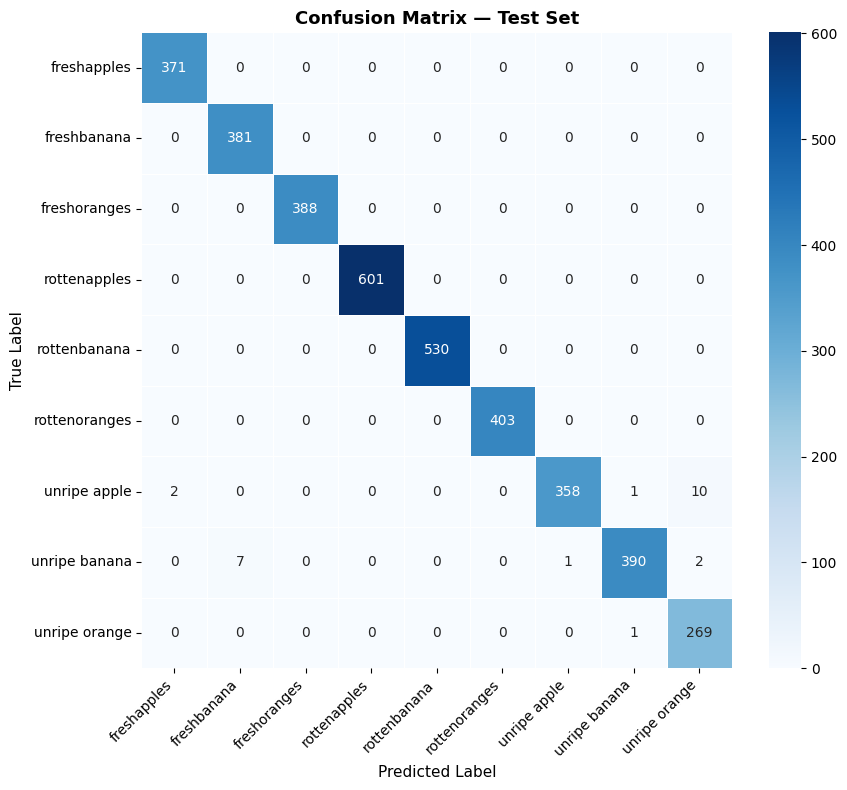

Saved /content/drive/MyDrive/cv_project_v2/saved_models/confusion_matrix.png


In [ ]:
# 2. CONFUSION MATRIX
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(max(8, NUM_CLASSES), max(6, NUM_CLASSES - 1)))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    linewidths=0.5
)
plt.title("Confusion Matrix — Test Set", fontsize=13, fontweight='bold')
plt.ylabel("True Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = os.path.join(SAVE_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {cm_path}")

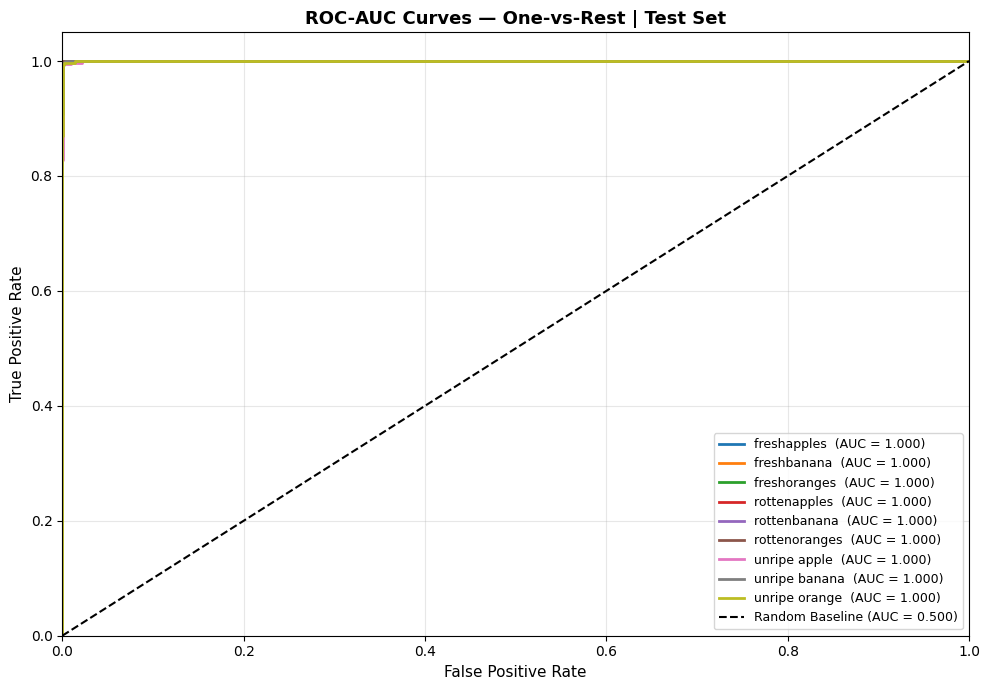

Saved /content/drive/MyDrive/cv_project_v2/saved_models/roc_auc_curves.png


In [ ]:
# 3. ROC-AUC CURVES (One-vs-Rest)
y_bin = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))

plt.figure(figsize=(10, 7))
for i, cls_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    auc_score   = roc_auc_score(y_bin[:, i], all_probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{cls_name}  (AUC = {auc_score:.3f})")

# Diagonal = random classifier baseline
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label="Random Baseline (AUC = 0.500)")
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.title("ROC-AUC Curves — One-vs-Rest | Test Set", fontsize=13, fontweight='bold')
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()

roc_path = os.path.join(SAVE_DIR, "roc_auc_curves.png")
plt.savefig(roc_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved {roc_path}")

## Step 11: Ablation Study - With vs Without Data Augmentation

Controlled variable: Data Augmentation (ON vs OFF)
All other hyperparameters held constant: same LR, batch size, epochs, seed.

This proves augmentation's role in reducing overfitting.

In [ ]:
def run_ablation(use_augmentation: bool, epochs: int = 15):
    """
    Train a fresh model with or without augmentation.
    Shows live epoch progress. Saves model to Drive.
    """
    import sys
    label = 'WITH Augmentation' if use_augmentation else 'WITHOUT Augmentation'
    print(f"\n{'─'*60}")
    print(f"  Ablation: {label}")
    print(f"{'─'*60}", flush=True)

    # Transforms
    tfm = train_transform if use_augmentation else base_transform
    dataset = CustomFruitDataset(TRAIN_DIR, transform=tfm)
    total   = len(dataset)

    # Verify no duplicates
    print(f"  Classes  : {dataset.classes}")
    print(f"  Total    : {total} images")

    # Split
    v_count = int(total * VAL_SPLIT)
    t_count = total - v_count
    gen     = torch.Generator().manual_seed(SEED)
    t_sub, v_sub = random_split(dataset, [t_count, v_count], generator=gen)

    # Val uses base_transform (no augmentation)
    v_clean = SubsetWithTransform(
        v_sub,
        CustomFruitDataset(TRAIN_DIR, transform=base_transform)
    )

    # DataLoaders
    t_loader = DataLoader(
        t_sub,   batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
    )
    v_loader = DataLoader(
        v_clean, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
    )

    # Fresh model
    m   = build_model(NUM_CLASSES, DEVICE)
    opt = optim.Adam(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    val_loss_hist = []
    val_acc_hist  = []

    print(f"\n  {'Epoch':<10} {'TrainLoss':>10} {'TrainAcc':>10} {'ValLoss':>10} {'ValAcc':>10} {'Time':>7}")
    print(f"  {'─'*55}", flush=True)

    for ep in range(1, epochs + 1):
        ep_start = time.time()

        # TRAIN
        m.train()
        t_loss_sum, t_correct, t_total = 0.0, 0, 0
        num_batches = len(t_loader)

        for b_idx, (imgs, lbls) in enumerate(t_loader):
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            opt.zero_grad()
            logits = m(imgs)
            loss   = criterion(logits, lbls)
            loss.backward()
            opt.step()

            t_loss_sum += loss.item() * imgs.size(0)
            preds       = logits.argmax(dim=1)
            t_correct  += (preds == lbls).sum().item()
            t_total    += lbls.size(0)

            # Live batch progress on same line
            print(
                f"\r  [{ep:02d}/{epochs}] Batch [{b_idx+1:03d}/{num_batches}] "
                f"Loss: {loss.item():.4f}",
                end='', flush=True
            )

        t_loss = t_loss_sum / t_total
        t_acc  = t_correct  / t_total

        # VALIDATE
        m.eval()
        vl_sum, v_correct, vn = 0.0, 0, 0
        with torch.no_grad():
            for imgs, lbls in v_loader:
                imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
                logits     = m(imgs)
                vl_sum    += criterion(logits, lbls).item() * imgs.size(0)
                preds      = logits.argmax(dim=1)
                v_correct += (preds == lbls).sum().item()
                vn        += lbls.size(0)

        v_loss = vl_sum    / vn
        v_acc  = v_correct / vn
        elapsed = time.time() - ep_start

        val_loss_hist.append(v_loss)
        val_acc_hist .append(v_acc)

        # Print final epoch summary (overwrites batch progress line)
        print(
            f"\r  [{ep:02d}/{epochs}]"
            f"  {t_loss:>10.4f}"
            f"  {t_acc:>10.4f}"
            f"  {v_loss:>10.4f}"
            f"  {v_acc:>10.4f}"
            f"  {elapsed:>6.1f}s",
            flush=True
        )

    # Save ablation model
    save_path = ABLATION_AUG_PATH if use_augmentation else ABLATION_NOAUG_PATH
    torch.save({
        "model_state_dict" : m.state_dict(),
        "val_loss_history" : val_loss_hist,
        "val_acc_history"  : val_acc_hist,
        "augmentation"     : use_augmentation,
        "class_to_idx"     : full_train_dataset.class_to_idx,
    }, save_path)
    print(f"\n  ✓ Model saved → {save_path}", flush=True)

    return val_loss_hist, val_acc_hist


# Run both conditions
ABLATION_EPOCHS = 25
losses_aug,    accs_aug    = run_ablation(use_augmentation=True,  epochs=ABLATION_EPOCHS)
losses_no_aug, accs_no_aug = run_ablation(use_augmentation=False, epochs=ABLATION_EPOCHS)


────────────────────────────────────────────────────────────
  Ablation: WITH Augmentation
────────────────────────────────────────────────────────────
    freshapples               → 1693 images  (label 0)
    freshbanana               → 1581 images  (label 1)
    freshoranges              → 1466 images  (label 2)
    rottenapples              → 2342 images  (label 3)
    rottenbanana              → 2224 images  (label 4)
    rottenoranges             → 1595 images  (label 5)
    unripe apple              → 1934 images  (label 6)
    unripe banana             → 2097 images  (label 7)
    unripe orange             → 1285 images  (label 8)
  Classes  : ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges', 'unripe apple', 'unripe banana', 'unripe orange']
  Total    : 16217 images
    freshapples               → 1693 images  (label 0)
    freshbanana               → 1581 images  (label 1)
    freshoranges              → 1466 images  (label 2)
  

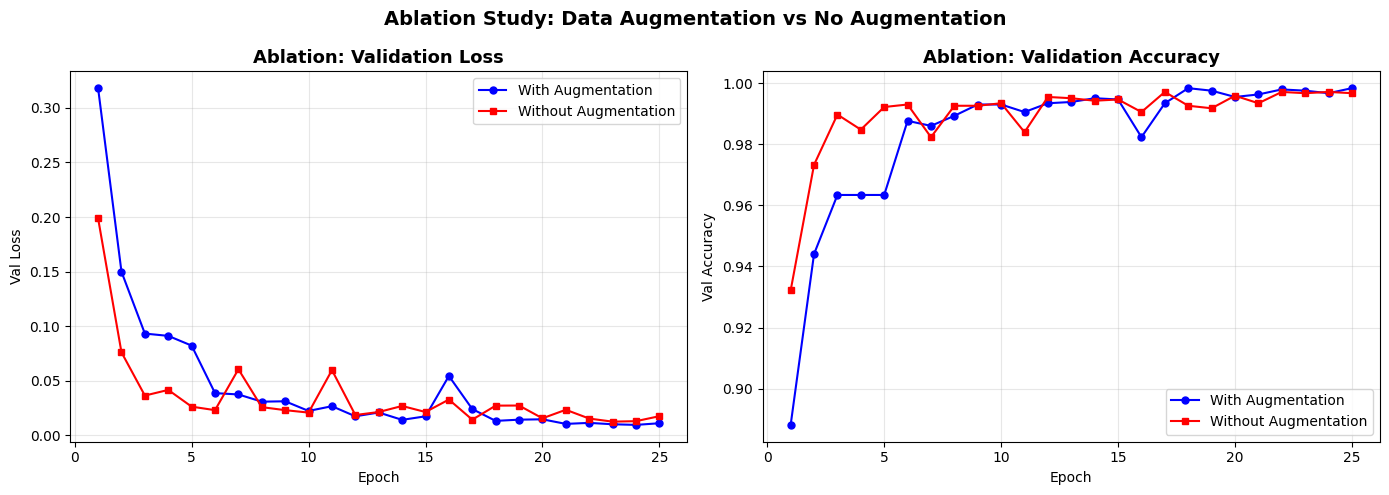


 Ablation Summary
  Condition                 Best ValLoss  Best ValAcc
  ──────────────────────────────────────────────────
  With Augmentation               0.0095       0.9984
  Without Augmentation            0.0125       0.9971

 Saved → /content/drive/MyDrive/cv_project_v2/saved_models/ablation_study.png


In [ ]:
# Plot Loss comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, ABLATION_EPOCHS+1), losses_aug,    'b-o', markersize=5,
         label="With Augmentation")
ax1.plot(range(1, ABLATION_EPOCHS+1), losses_no_aug, 'r-s', markersize=5,
         label="Without Augmentation")
ax1.set_title("Ablation: Validation Loss", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Val Loss")
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(range(1, ABLATION_EPOCHS+1), accs_aug,    'b-o', markersize=5,
         label="With Augmentation")
ax2.plot(range(1, ABLATION_EPOCHS+1), accs_no_aug, 'r-s', markersize=5,
         label="Without Augmentation")
ax2.set_title("Ablation: Validation Accuracy", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Val Accuracy")
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle("Ablation Study: Data Augmentation vs No Augmentation",
             fontsize=14, fontweight='bold')
plt.tight_layout()

ablation_path = os.path.join(SAVE_DIR, "ablation_study.png")
plt.savefig(ablation_path, dpi=150, bbox_inches='tight')
plt.show()

# Summary table
print("\n Ablation Summary")
print(f"  {'Condition':<25} {'Best ValLoss':>12}  {'Best ValAcc':>11}")
print(f"  {'─'*50}")
print(f"  {'With Augmentation':<25} {min(losses_aug):>12.4f}  {max(accs_aug):>11.4f}")
print(f"  {'Without Augmentation':<25} {min(losses_no_aug):>12.4f}  {max(accs_no_aug):>11.4f}")
print(f"\n Saved → {ablation_path}")